## 1. Environment and reproducibility

The original paper used TensorFlow/Keras and a GPU. This notebook uses TensorFlow/Keras and MNE-Python. The model architecture and the published SMR preprocessing/evaluation design are implemented below. Random seeds are fixed for repeatability within the current software environment.

In [1]:
%pip install -q mne scipy scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import gc
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mne
from scipy.io import loadmat
from scipy.signal import welch, freqz
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models, constraints, callbacks

mne.set_log_level("ERROR")

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
MNE: 1.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Experiment settings

The values below follow the paper where they are stated. The paper specifies 500 maximum epochs and the 90-fold cross-subject design. It does not state the mini-batch size or early-stopping patience in the SMR section; this notebook fixes those implementation settings explicitly.

In [3]:
INPUT_ROOT = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working/eegnet_c1_reproduction")
EXTRACT_DIR = WORK_DIR / "extracted_inputs"
OUTPUT_DIR = WORK_DIR / "results"

WORK_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SUBJECTS = [f"A{i:02d}" for i in range(1, 10)]

ORIGINAL_SFREQ = 250
TARGET_SFREQ = 128
LOW_CUTOFF = 4.0
HIGH_CUTOFF = 40.0
EPOCH_START = 0.5
EPOCH_END = 2.5
N_CHANNELS = 22
N_CLASSES = 4

F1 = 8
DEPTH_MULTIPLIER = 2
F2 = F1 * DEPTH_MULTIPLIER
TEMPORAL_KERNEL = 32
DROPOUT_RATE = 0.25
MAX_EPOCHS = 500
BATCH_SIZE = 32
EARLY_STOPPING_PATIENCE = 50
N_REPEATS = 10

AUTO_DOWNLOAD_TEST_LABELS = True

CLASS_NAMES = ["Left hand", "Right hand", "Feet", "Tongue"]
PAPER_TRUE_LABELS_URL = "https://www.bbci.de/competition/iv/results/ds2a/true_labels.zip"

print("Input directory:", INPUT_ROOT)
print("Output directory:", OUTPUT_DIR)
print("Experiment folds:", len(SUBJECTS) * N_REPEATS)

Input directory: /kaggle/input
Output directory: /kaggle/working/eegnet_c1_reproduction/results
Experiment folds: 90


## 3. Locate the raw dataset and official test labels

The loader searches recursively under `/kaggle/input`. It also extracts GDF or true-label ZIP archives found there. If evaluation `.mat` label files are missing, it attempts to retrieve the official label archive from the competition site.

In [5]:
import os
import re
import zipfile
import requests
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working/eegnet_c1_reproduction")
EXTRACT_DIR = WORK_DIR / "extracted_inputs"
OUTPUT_DIR = WORK_DIR / "results"

WORK_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SUBJECTS = [f"A{i:02d}" for i in range(1, 10)]

GDF_URL = (
    "https://www.bbci.de/competition/download/competition_iv/"
    "BCICIV_2a_gdf.zip"
)

LABEL_URL = (
    "https://www.bbci.de/competition/iv/results/ds2a/"
    "true_labels.zip"
)

EXPECTED_GDF = {
    f"{subject}{session}.gdf".lower()
    for subject in SUBJECTS
    for session in ("T", "E")
}

EXPECTED_LABELS = {
    f"{subject}E.mat".lower()
    for subject in SUBJECTS
}


def find_files_by_name(filename):
    matches = []

    for root in [INPUT_ROOT, EXTRACT_DIR]:
        if root.exists():
            matches.extend(
                p for p in root.rglob("*")
                if p.is_file() and p.name.lower() == filename.lower()
            )

    return sorted(set(matches))


def extract_matching_files(zip_path, destination):
    destination.mkdir(parents=True, exist_ok=True)
    extracted = []

    with zipfile.ZipFile(zip_path, "r") as archive:
        for member in archive.infolist():
            filename = Path(member.filename).name
            lower_name = filename.lower()

            if lower_name in EXPECTED_GDF or lower_name in EXPECTED_LABELS:
                if member.is_dir():
                    continue

                output_path = destination / filename

                with archive.open(member) as source:
                    with open(output_path, "wb") as target:
                        while True:
                            chunk = source.read(1024 * 1024)
                            if not chunk:
                                break
                            target.write(chunk)

                extracted.append(filename)

    return extracted


def extract_input_archives():
    for archive_path in INPUT_ROOT.rglob("*"):
        if not archive_path.is_file():
            continue

        if archive_path.suffix.lower() != ".zip":
            continue

        try:
            extracted = extract_matching_files(
                archive_path,
                EXTRACT_DIR / archive_path.stem
            )

            if extracted:
                print(
                    f"Extracted {len(extracted)} relevant files "
                    f"from {archive_path.name}"
                )

        except zipfile.BadZipFile:
            print(f"Skipping invalid ZIP: {archive_path.name}")


def download_archive(url, destination):
    temporary_path = destination.with_suffix(".part")

    print(f"Downloading: {destination.name}")

    with requests.get(
        url,
        stream=True,
        timeout=(30, 300),
        headers={"User-Agent": "Mozilla/5.0"}
    ) as response:

        response.raise_for_status()

        total_size = int(response.headers.get("content-length", 0))
        downloaded = 0

        with open(temporary_path, "wb") as file:
            for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
                if chunk:
                    file.write(chunk)
                    downloaded += len(chunk)

                    if total_size:
                        print(
                            f"\rDownloaded: {downloaded / 1024**2:.1f} / "
                            f"{total_size / 1024**2:.1f} MB",
                            end=""
                        )

    print()

    if not zipfile.is_zipfile(temporary_path):
        temporary_path.unlink(missing_ok=True)
        raise RuntimeError(
            f"{destination.name} is not a valid ZIP archive. "
            "Check Kaggle Internet access."
        )

    temporary_path.replace(destination)
    print(f"Download completed: {destination.name}")


def ensure_gdf_recordings():
    missing = [
        name for name in EXPECTED_GDF
        if not find_files_by_name(name)
    ]

    if not missing:
        print("All 18 GDF recordings are already available.")
        return

    print(f"Missing GDF recordings: {len(missing)}")

    archive_path = WORK_DIR / "BCICIV_2a_gdf.zip"

    if not archive_path.exists() or not zipfile.is_zipfile(archive_path):
        download_archive(GDF_URL, archive_path)

    extracted = extract_matching_files(
        archive_path,
        EXTRACT_DIR / "official_bci2a_gdf"
    )

    print(f"Extracted GDF recordings: {len(extracted)}")


def ensure_evaluation_labels():
    missing = [
        name for name in EXPECTED_LABELS
        if not find_files_by_name(name)
    ]

    if not missing:
        print("All 9 evaluation label files are available.")
        return

    archive_path = WORK_DIR / "true_labels.zip"

    if not archive_path.exists() or not zipfile.is_zipfile(archive_path):
        download_archive(LABEL_URL, archive_path)

    extracted = extract_matching_files(
        archive_path,
        EXTRACT_DIR / "official_true_labels"
    )

    print(f"Extracted evaluation labels: {len(extracted)}")


# Search the datasets already attached through Kaggle Add Input
extract_input_archives()

# Download missing files from the official competition source
ensure_evaluation_labels()
ensure_gdf_recordings()


# Final verification
missing_gdf = [
    name for name in sorted(EXPECTED_GDF)
    if not find_files_by_name(name)
]

missing_labels = [
    name for name in sorted(EXPECTED_LABELS)
    if not find_files_by_name(name)
]

if missing_gdf or missing_labels:
    raise FileNotFoundError(
        "Dataset verification failed.\n"
        f"Missing GDF recordings: {missing_gdf}\n"
        f"Missing evaluation labels: {missing_labels}\n"
        "Enable Internet in Kaggle Notebook Settings and rerun this cell."
    )

print("\nDataset verification successful.")

for subject in SUBJECTS:
    train_file = find_files_by_name(f"{subject}T.gdf")[0]
    eval_file = find_files_by_name(f"{subject}E.gdf")[0]
    label_file = find_files_by_name(f"{subject}E.mat")[0]

    print(f"{subject}:")
    print(f"  Training:   {train_file}")
    print(f"  Evaluation: {eval_file}")
    print(f"  Labels:     {label_file}")

print("\nAll 18 GDF recordings and 9 evaluation label files are ready.")
print("Proceed to the next preprocessing cell.")

All 9 evaluation label files are available.
Missing GDF recordings: 18
Downloading: BCICIV_2a_gdf.zip
Downloaded: 419.6 / 419.6 MB
Download completed: BCICIV_2a_gdf.zip
Extracted GDF recordings: 18

Dataset verification successful.
A01:
  Training:   /kaggle/working/eegnet_c1_reproduction/extracted_inputs/official_bci2a_gdf/A01T.gdf
  Evaluation: /kaggle/working/eegnet_c1_reproduction/extracted_inputs/official_bci2a_gdf/A01E.gdf
  Labels:     /kaggle/working/eegnet_c1_reproduction/extracted_inputs/official_true_labels/A01E.mat
A02:
  Training:   /kaggle/working/eegnet_c1_reproduction/extracted_inputs/official_bci2a_gdf/A02T.gdf
  Evaluation: /kaggle/working/eegnet_c1_reproduction/extracted_inputs/official_bci2a_gdf/A02E.gdf
  Labels:     /kaggle/working/eegnet_c1_reproduction/extracted_inputs/official_true_labels/A02E.mat
A03:
  Training:   /kaggle/working/eegnet_c1_reproduction/extracted_inputs/official_bci2a_gdf/A03T.gdf
  Evaluation: /kaggle/working/eegnet_c1_reproduction/extracted_

## 4. Load and preprocess the recordings

The paper's SMR procedure uses 22 EEG channels, resampling to 128 Hz, a 4–40 Hz passband and a 2-second epoch from 0.5 to 2.5 seconds after cue onset. The GDF training session contains class cue markers 769–772. The evaluation GDF uses the unknown-cue marker 783; its true class labels are loaded separately from the official `.mat` label files.

The artifact marker 1023 is counted for the quality report. This notebook does not remove trials based on that marker, so it does not silently introduce a trial-rejection rule that is not specified in the paper's SMR method. Signals are converted from MNE's SI voltage units (volts) to microvolts before model training.

In [6]:
BCI2A_CHANNELS = [
    "Fz", "FC3", "FC1", "FCz", "FC2", "FC4", "C5", "C3", "C1", "Cz", "C2",
    "C4", "C6", "CP3", "CP1", "CPz", "CP2", "CP4", "P1", "Pz", "P2", "POz"
]


def find_one_file(filename):
    matches = find_files_by_name(filename)
    if not matches:
        raise FileNotFoundError(f"Could not find {filename} under /kaggle/input or extracted archives.")
    if len(matches) > 1:
        print(f"Multiple copies of {filename} found. Using: {matches[0]}")
    return matches[0]


def annotation_code(description):
    numbers = re.findall(r"\d+", str(description))
    return int(numbers[-1]) if numbers else None


def get_eeg_picks(raw):
    channel_types = raw.get_channel_types()
    eeg_picks = [i for i, kind in enumerate(channel_types) if kind == "eeg"]

    if len(eeg_picks) >= N_CHANNELS:
        return eeg_picks[:N_CHANNELS]

    fallback = []
    for index, name in enumerate(raw.ch_names):
        lower = name.lower()
        if any(token in lower for token in ("eog", "ecg", "emg", "stim", "status")):
            continue
        if channel_types[index] not in ("stim", "eog", "ecg", "emg"):
            fallback.append(index)

    if len(fallback) < N_CHANNELS:
        raise ValueError(
            f"Only {len(fallback)} possible EEG channels were found; expected {N_CHANNELS}. "
            f"Channels: {raw.ch_names}"
        )
    return fallback[:N_CHANNELS]


def count_annotation_code(raw, wanted_code):
    return sum(annotation_code(description) == wanted_code for description in raw.annotations.description)


def extract_epochs_from_gdf(path, session):
    raw = mne.io.read_raw_gdf(path, preload=True, verbose="ERROR")
    artifact_count = count_annotation_code(raw, 1023)
    original_channels = raw.ch_names.copy()

    picks = get_eeg_picks(raw)
    raw.pick(picks)
    raw.resample(TARGET_SFREQ, npad="auto", verbose="ERROR")
    raw.filter(
        l_freq=LOW_CUTOFF,
        h_freq=HIGH_CUTOFF,
        method="fir",
        phase="zero",
        verbose="ERROR"
    )

    events, event_id = mne.events_from_annotations(raw, verbose="ERROR")
    code_to_event = {}
    for description, event_value in event_id.items():
        code = annotation_code(description)
        if code is not None:
            code_to_event[code] = event_value

    if session == "T":
        wanted_codes = [769, 770, 771, 772]
    else:
        wanted_codes = [783]

    missing_codes = [code for code in wanted_codes if code not in code_to_event]
    if missing_codes:
        raise ValueError(
            f"Required event codes {missing_codes} were not found in {path.name}. "
            f"Available annotation descriptions: {list(event_id.keys())}"
        )

    wanted_event_values = [code_to_event[code] for code in wanted_codes]
    selected_events = events[np.isin(events[:, 2], wanted_event_values)]

    epoch_end_exclusive = EPOCH_END - (1.0 / TARGET_SFREQ)
    epochs = mne.Epochs(
        raw,
        selected_events,
        event_id=None,
        tmin=EPOCH_START,
        tmax=epoch_end_exclusive,
        baseline=None,
        preload=True,
        reject_by_annotation=False,
        verbose="ERROR"
    )

    X = epochs.get_data().astype(np.float32) * 1e6
    event_codes = epochs.events[:, 2]

    if session == "T":
        inverse_map = {event_value: class_index for class_index, event_value in enumerate(wanted_event_values)}
        y = np.asarray([inverse_map[value] for value in event_codes], dtype=np.int64)
    else:
        y = None

    cleaned_names = []
    for name in raw.ch_names:
        cleaned = re.sub(r"^(EEG|EOG)[\s_\-]*", "", name, flags=re.IGNORECASE)
        cleaned = re.sub(r"[-_](REF|LE|RE)$", "", cleaned, flags=re.IGNORECASE)
        cleaned_names.append(cleaned)

    return {
        "X": X,
        "y": y,
        "channel_names": cleaned_names,
        "sfreq": float(raw.info["sfreq"]),
        "n_channels": len(raw.ch_names),
        "n_events": len(selected_events),
        "artifact_markers": artifact_count,
        "original_channel_names": original_channels
    }


def load_test_labels(subject):
    label_path = find_one_file(f"{subject}E.mat")
    payload = loadmat(label_path)

    if "classlabel" in payload:
        labels = np.asarray(payload["classlabel"]).squeeze()
    else:
        candidates = []
        for key, value in payload.items():
            if key.startswith("__"):
                continue
            array = np.asarray(value)
            if array.size == 288 and np.issubdtype(array.dtype, np.number):
                candidates.append((key, array.squeeze()))
        if len(candidates) != 1:
            raise ValueError(
                f"Could not identify the class labels in {label_path.name}. "
                f"MAT variables found: {[key for key in payload if not key.startswith('__')]}"
            )
        labels = candidates[0][1]

    labels = np.asarray(labels).reshape(-1).astype(np.int64)
    if not np.all(np.isin(labels, [1, 2, 3, 4])):
        raise ValueError(f"Unexpected class values in {label_path.name}: {np.unique(labels)}")
    return labels - 1


subject_data = {}
quality_rows = []
reference_channel_names = None

for subject in SUBJECTS:
    training_path = find_one_file(f"{subject}T.gdf")
    evaluation_path = find_one_file(f"{subject}E.gdf")

    training = extract_epochs_from_gdf(training_path, "T")
    evaluation = extract_epochs_from_gdf(evaluation_path, "E")
    evaluation["y"] = load_test_labels(subject)

    if training["X"].shape[1] != N_CHANNELS or evaluation["X"].shape[1] != N_CHANNELS:
        raise ValueError(f"{subject}: expected {N_CHANNELS} EEG channels.")

    if training["X"].shape[-1] != 256 or evaluation["X"].shape[-1] != 256:
        raise ValueError(
            f"{subject}: expected 256 time samples per epoch, got "
            f"training {training['X'].shape[-1]} and evaluation {evaluation['X'].shape[-1]}."
        )

    if len(evaluation["y"]) != len(evaluation["X"]):
        raise ValueError(
            f"{subject}: evaluation labels ({len(evaluation['y'])}) do not match "
            f"evaluation epochs ({len(evaluation['X'])}). Check that the correct official label files were attached."
        )

    if reference_channel_names is None:
        reference_channel_names = training["channel_names"]
    elif training["channel_names"] != reference_channel_names:
        print(f"Warning: {subject} channel names differ from A01. The channel order from each GDF is retained.")

    subject_data[subject] = {"train": training, "test": evaluation}

    quality_rows.append({
        "subject": subject,
        "training_trials": len(training["X"]),
        "evaluation_trials": len(evaluation["X"]),
        "training_artifact_markers_1023": training["artifact_markers"],
        "evaluation_artifact_markers_1023": evaluation["artifact_markers"],
        "EEG_channels": training["n_channels"],
        "sampling_rate_after_resampling": training["sfreq"],
        "epoch_samples": training["X"].shape[-1],
        "training_label_counts": np.bincount(training["y"], minlength=4).tolist(),
        "evaluation_label_counts": np.bincount(evaluation["y"], minlength=4).tolist(),
        "non_finite_training_values": int((~np.isfinite(training["X"])).sum()),
        "non_finite_evaluation_values": int((~np.isfinite(evaluation["X"])).sum())
    })

    print(
        f"{subject}: training {training['X'].shape}, evaluation {evaluation['X'].shape}, "
        f"evaluation labels {evaluation['y'].shape}"
    )

quality_df = pd.DataFrame(quality_rows)
display(quality_df)

assert len(subject_data) == 9
assert all(len(subject_data[s]["train"]["X"]) == 288 for s in SUBJECTS), "Expected 288 training trials per subject."
assert all(len(subject_data[s]["test"]["X"]) == 288 for s in SUBJECTS), "Expected 288 evaluation trials per subject."

A01: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A02: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A03: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A04: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A05: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A06: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A07: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A08: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)
A09: training (288, 22, 256), evaluation (288, 22, 256), evaluation labels (288,)


,subject,training_trials,evaluation_trials,training_artifact_markers_1023,evaluation_artifact_markers_1023,EEG_channels,sampling_rate_after_resampling,epoch_samples,training_label_counts,evaluation_label_counts,non_finite_training_values,non_finite_evaluation_values
0,A01,288,288,15,7,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
1,A02,288,288,18,5,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
2,A03,288,288,18,15,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
3,A04,288,288,26,60,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
4,A05,288,288,26,12,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
5,A06,288,288,69,73,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
6,A07,288,288,17,11,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
7,A08,288,288,24,17,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
8,A09,288,288,51,24,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0


## 5. Data quality checks and signal inspection

The checks below report channel variability, non-finite values, trial counts and artifact markers. Artifact markers are reported but not used to discard trials. This keeps the trial-selection policy visible and avoids adding an undocumented rejection step.

,channel,training_session_std_uV
6,C5,5.309039
12,C6,6.120401
7,C3,6.258642
13,CP3,6.428822
18,P1,6.525883
14,CP1,6.558979
1,FC3,6.612030
20,P2,6.652369
19,Pz,6.655690
16,CP2,6.694200


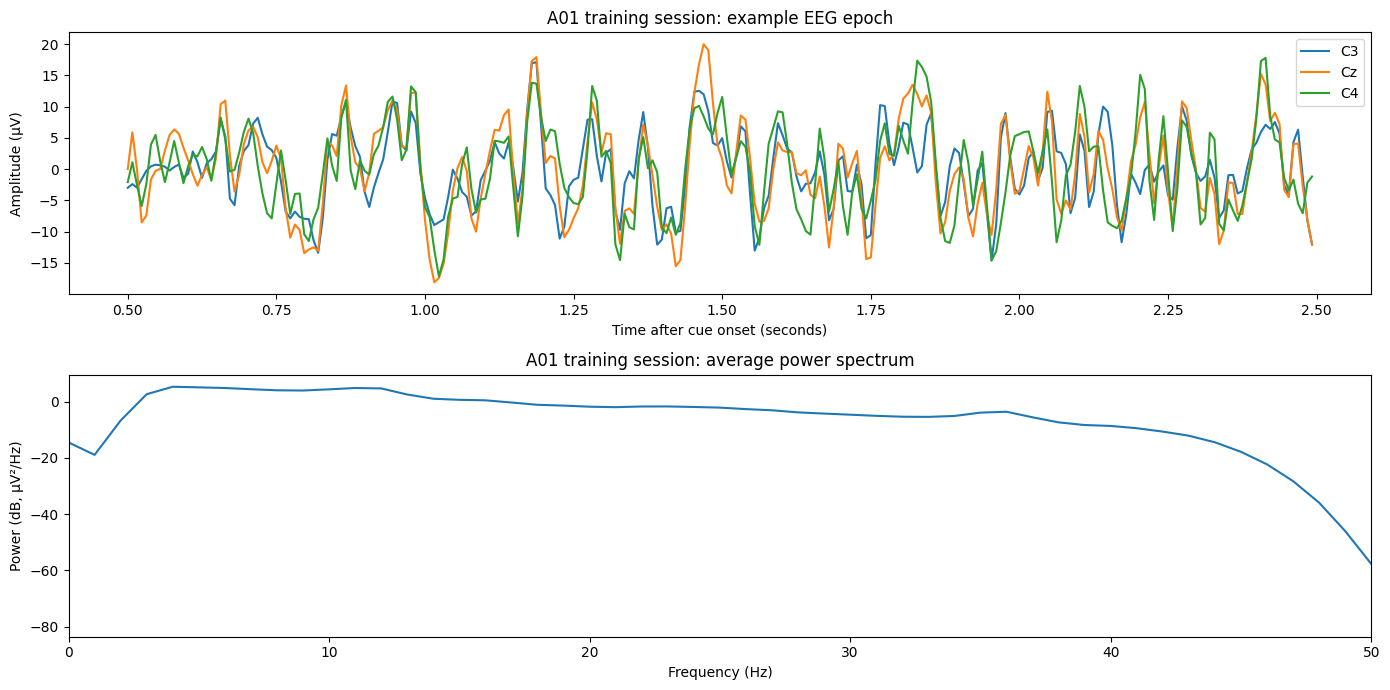

In [7]:
quality_df.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index=False)

example_subject = "A01"
example_X = subject_data[example_subject]["train"]["X"]
example_y = subject_data[example_subject]["train"]["y"]

channel_std = np.std(example_X, axis=(0, 2))
channel_qc = pd.DataFrame({
    "channel": BCI2A_CHANNELS,
    "training_session_std_uV": channel_std
}).sort_values("training_session_std_uV")

display(channel_qc)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
time = np.arange(example_X.shape[-1]) / TARGET_SFREQ + EPOCH_START

for channel_index in [7, 9, 11]:
    axes[0].plot(time, example_X[0, channel_index], label=BCI2A_CHANNELS[channel_index])
axes[0].set_title(f"{example_subject} training session: example EEG epoch")
axes[0].set_xlabel("Time after cue onset (seconds)")
axes[0].set_ylabel("Amplitude (µV)")
axes[0].legend()

frequencies, power = welch(example_X, fs=TARGET_SFREQ, axis=-1, nperseg=128)
mean_power = np.mean(power, axis=(0, 1))
axes[1].plot(frequencies, 10 * np.log10(mean_power + 1e-12))
axes[1].set_xlim(0, 50)
axes[1].set_title(f"{example_subject} training session: average power spectrum")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Power (dB, µV²/Hz)")
plt.tight_layout()
plt.show()

if not np.isfinite(example_X).all():
    raise ValueError("Non-finite EEG values were found. Inspect the data quality summary before training.")

## 6. EEGNet-8,2 model

The model follows the paper's EEGNet architecture: temporal convolution, depthwise spatial convolution, separable temporal convolution and a softmax classifier. For the SMR experiment, the paper uses a temporal kernel length of 32 samples, EEGNet-8,2, and dropout 0.25 for cross-subject training. The expected parameter count for the 22-channel, 256-sample input is 1,716.

In [10]:

def build_eegnet(channels=N_CHANNELS, samples=256):
    inputs = layers.Input(shape=(channels, samples, 1), name="eeg_input")

    x = layers.Conv2D(
        filters=F1,
        kernel_size=(1, TEMPORAL_KERNEL),
        padding="same",
        use_bias=False,
        name="temporal_conv"
    )(inputs)

    x = layers.BatchNormalization(
        axis=-1,
        name="bn_temporal"
    )(x)

    x = layers.DepthwiseConv2D(
        kernel_size=(channels, 1),
        depth_multiplier=DEPTH_MULTIPLIER,
        use_bias=False,
        depthwise_constraint=constraints.max_norm(1.0),
        name="spatial_filter"
    )(x)

    x = layers.BatchNormalization(
        axis=-1,
        name="bn_spatial"
    )(x)

    x = layers.Activation("elu")(x)
    x = layers.AveragePooling2D(pool_size=(1, 4))(x)
    x = layers.Dropout(DROPOUT_RATE)(x)

    x = layers.SeparableConv2D(
        filters=F2,
        kernel_size=(1, 16),
        padding="same",
        use_bias=False,
        name="separable_temporal"
    )(x)

    x = layers.BatchNormalization(
        axis=-1,
        name="bn_separable"
    )(x)

    x = layers.Activation("elu")(x)
    x = layers.AveragePooling2D(pool_size=(1, 8))(x)
    x = layers.Dropout(DROPOUT_RATE)(x)

    x = layers.Flatten()(x)

    outputs = layers.Dense(
        N_CLASSES,
        activation="softmax",
        kernel_constraint=constraints.max_norm(0.25),
        name="classifier"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="EEGNet_8_2"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model_check = build_eegnet()

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in model_check.trainable_weights
)

non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in model_check.non_trainable_weights
)

total_params = model_check.count_params()

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)
print("Total parameters:", total_params)

assert trainable_params == 1716, \
    "Trainable parameter count differs from the paper."

assert non_trainable_params == 80, \
    "Unexpected non-trainable parameter count."

assert total_params == 1796, \
    "Unexpected total parameter count."

print("\nEEGNet-8,2 parameter verification successful.")

model_check.summary()

del model_check
tf.keras.backend.clear_session()
gc.collect()


Trainable parameters: 1716
Non-trainable parameters: 80
Total parameters: 1796

EEGNet-8,2 parameter verification successful.


Model: "EEGNet_8_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ eeg_input (InputLayer)          │ (None, 22, 256, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_conv (Conv2D)          │ (None, 22, 256, 8)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_temporal                     │ (None, 22, 256, 8)     │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_filter                  │ (None, 1, 256, 16)     │           352 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_spatial (BatchNormalization) │ (None, 1, 256, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1, 256, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 64, 16)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 64, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_temporal              │ (None, 1, 64, 16)      │           512 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_separable                    │ (None, 1, 64, 16)      │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 1, 64, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 1, 8, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,796 (7.02 KB)

 Trainable params: 1,716 (6.70 KB)

 Non-trainable params: 80 (320.00 B)

0

## 7. Cross-subject evaluation: 90 folds

For each target subject:

- Keep that subject's training session out of both training and validation.
- Randomly select five of the other eight subjects for the training set.
- Use the remaining three subjects for validation.
- Evaluate only on the held-out target subject's evaluation session.
- Repeat the five/three subject split ten times.

The paper reports the mean and standard error over the 90 folds. The primary metric below is accuracy; Cohen's kappa is also reported as a supplementary metric. Test-set labels are used only after the model and best validation weights have been selected.

In [11]:
def concatenate_sessions(subject_list, session_name):
    X_parts = [subject_data[subject][session_name]["X"] for subject in subject_list]
    y_parts = [subject_data[subject][session_name]["y"] for subject in subject_list]
    X = np.concatenate(X_parts, axis=0)
    y = np.concatenate(y_parts, axis=0)
    return X, y


def prepare_model_input(X):
    return X[..., np.newaxis].astype(np.float32)


def run_cross_subject_experiment():
    fold_rows = []
    interpretation_model = None
    interpretation_subject = None
    interpretation_repeat = None

    for target_index, target_subject in enumerate(SUBJECTS):
        other_subjects = [subject for subject in SUBJECTS if subject != target_subject]
        X_test = prepare_model_input(subject_data[target_subject]["test"]["X"])
        y_test = subject_data[target_subject]["test"]["y"]

        for repeat in range(N_REPEATS):
            fold_seed = SEED + target_index * 100 + repeat
            rng = np.random.default_rng(fold_seed)
            selected_train = sorted(rng.choice(other_subjects, size=5, replace=False).tolist())
            selected_validation = sorted(subject for subject in other_subjects if subject not in selected_train)

            X_train, y_train = concatenate_sessions(selected_train, "train")
            X_val, y_val = concatenate_sessions(selected_validation, "train")

            X_train = prepare_model_input(X_train)
            X_val = prepare_model_input(X_val)
            y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=N_CLASSES)
            y_val_cat = tf.keras.utils.to_categorical(y_val, num_classes=N_CLASSES)

            tf.keras.backend.clear_session()
            gc.collect()
            tf.keras.utils.set_random_seed(fold_seed)

            model = build_eegnet(channels=X_train.shape[1], samples=X_train.shape[2])
            stop_callback = callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
                verbose=0
            )

            history = model.fit(
                X_train,
                y_train_cat,
                validation_data=(X_val, y_val_cat),
                epochs=MAX_EPOCHS,
                batch_size=BATCH_SIZE,
                shuffle=True,
                callbacks=[stop_callback],
                verbose=0
            )

            probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
            predictions = np.argmax(probabilities, axis=1)
            accuracy = accuracy_score(y_test, predictions)
            kappa = cohen_kappa_score(y_test, predictions)

            fold_rows.append({
                "target_subject": target_subject,
                "repeat": repeat + 1,
                "training_subjects": ",".join(selected_train),
                "validation_subjects": ",".join(selected_validation),
                "training_trials": len(X_train),
                "validation_trials": len(X_val),
                "test_trials": len(X_test),
                "best_validation_loss": float(np.min(history.history["val_loss"])),
                "epochs_completed": len(history.history["loss"]),
                "test_accuracy": float(accuracy),
                "test_kappa": float(kappa)
            })

            if target_subject == "A01" and repeat == 0:
                interpretation_model = model
                interpretation_subject = target_subject
                interpretation_repeat = repeat + 1
            else:
                del model

            print(
                f"{target_subject} | repeat {repeat + 1:02d}/{N_REPEATS} | "
                f"accuracy={accuracy:.4f} | epochs={len(history.history['loss'])}"
            )

    return pd.DataFrame(fold_rows), interpretation_model, interpretation_subject, interpretation_repeat


fold_results, interpretation_model, interpretation_subject, interpretation_repeat = run_cross_subject_experiment()
fold_results.to_csv(OUTPUT_DIR / "eegnet_90_fold_results.csv", index=False)

print("Completed folds:", len(fold_results))
assert len(fold_results) == 90

E0000 00:00:1794751129.839224      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EEGNet_8_2_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


A01 | repeat 01/10 | accuracy=0.4722 | epochs=59
A01 | repeat 02/10 | accuracy=0.4097 | epochs=73


E0000 00:00:1794751210.168228      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EEGNet_8_2_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


A01 | repeat 03/10 | accuracy=0.6215 | epochs=69
A01 | repeat 04/10 | accuracy=0.6007 | epochs=81


E0000 00:00:1794751295.485091      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EEGNet_8_2_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


A01 | repeat 05/10 | accuracy=0.6597 | epochs=107


... (86 outputs left out)

E0000 00:00:1794754706.695991      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EEGNet_8_2_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


A09 | repeat 07/10 | accuracy=0.2847 | epochs=55
A09 | repeat 08/10 | accuracy=0.4271 | epochs=65


E0000 00:00:1794754778.351376      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EEGNet_8_2_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


A09 | repeat 09/10 | accuracy=0.4028 | epochs=81
A09 | repeat 10/10 | accuracy=0.3889 | epochs=127
Completed folds: 90


## 8. Results and comparison with the paper

The paper's Figure 5 presents cross-subject SMR accuracy as a bar chart rather than a numerical table. The reference values below are therefore **visual approximations read from Figure 5**, not exact tabulated paper results. The exact reproduction result from this notebook is calculated from the 90 folds and is reported separately.

,Metric,Value
0,Number of folds,90.000000
1,Mean accuracy,0.377392
2,Standard deviation,0.136181
3,Standard error of the mean,0.014355
4,Two standard errors,0.028709
5,Mean Cohen's kappa,0.169856
6,Chance-level accuracy,0.250000


,target_subject,mean_accuracy,std_accuracy,folds,mean_accuracy_percent
0,A01,0.531944,0.124127,10,53.194444
1,A02,0.279514,0.025265,10,27.951389
2,A03,0.536806,0.134729,10,53.680556
3,A04,0.332986,0.055639,10,33.298611
4,A05,0.262847,0.015704,10,26.284722
5,A06,0.295139,0.035674,10,29.513889
6,A07,0.289236,0.054362,10,28.923611
7,A08,0.507639,0.143040,10,50.763889
8,A09,0.360417,0.060425,10,36.041667


,Method,Paper Figure 5 (visual estimate)
0,FBCSP,0.320000
1,DeepConvNet,0.390000
2,ShallowConvNet,0.400000
3,"EEGNet-4,2",0.400000
4,"EEGNet-8,2",0.400000
5,"Our EEGNet-8,2 reproduction",0.377392


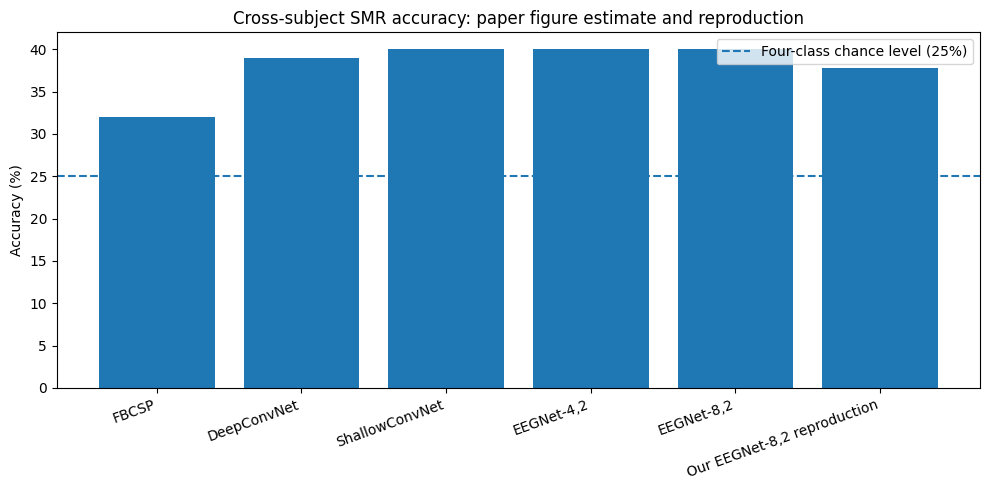

Our 90-fold mean accuracy: 37.74%
SEM: 1.44 percentage points
Paper Figure 5 reports that the cross-subject CNN models perform similarly and slightly outperform FBCSP.


In [12]:
mean_accuracy = fold_results["test_accuracy"].mean()
std_accuracy = fold_results["test_accuracy"].std(ddof=1)
sem_accuracy = std_accuracy / np.sqrt(len(fold_results))
mean_kappa = fold_results["test_kappa"].mean()

summary_table = pd.DataFrame({
    "Metric": ["Number of folds", "Mean accuracy", "Standard deviation", "Standard error of the mean", "Two standard errors", "Mean Cohen's kappa", "Chance-level accuracy"],
    "Value": [
        len(fold_results),
        mean_accuracy,
        std_accuracy,
        sem_accuracy,
        2 * sem_accuracy,
        mean_kappa,
        1.0 / N_CLASSES
    ]
})

display(summary_table)

subject_summary = (
    fold_results.groupby("target_subject")["test_accuracy"]
    .agg(mean_accuracy="mean", std_accuracy="std", folds="count")
    .reset_index()
)
subject_summary["mean_accuracy_percent"] = 100 * subject_summary["mean_accuracy"]
subject_summary.to_csv(OUTPUT_DIR / "subject_accuracy_summary.csv", index=False)
display(subject_summary)

PAPER_FIGURE5_APPROX = {
    "FBCSP": 0.32,
    "DeepConvNet": 0.39,
    "ShallowConvNet": 0.40,
    "EEGNet-4,2": 0.40,
    "EEGNet-8,2": 0.40
}

comparison_table = pd.DataFrame([
    {"Method": method, "Paper Figure 5 (visual estimate)": value}
    for method, value in PAPER_FIGURE5_APPROX.items()
])
comparison_table.loc[len(comparison_table)] = {
    "Method": "Our EEGNet-8,2 reproduction",
    "Paper Figure 5 (visual estimate)": mean_accuracy
}
comparison_table.to_csv(OUTPUT_DIR / "paper_comparison.csv", index=False)
display(comparison_table)

plt.figure(figsize=(10, 5))
plt.bar(comparison_table["Method"], comparison_table["Paper Figure 5 (visual estimate)"] * 100)
plt.axhline(25, linestyle="--", label="Four-class chance level (25%)")
plt.ylabel("Accuracy (%)")
plt.title("Cross-subject SMR accuracy: paper figure estimate and reproduction")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Our 90-fold mean accuracy: {mean_accuracy * 100:.2f}%")
print(f"SEM: {sem_accuracy * 100:.2f} percentage points")
print("Paper Figure 5 reports that the cross-subject CNN models perform similarly and slightly outperform FBCSP.")

## 9. Model interpretation

The paper discusses temporal convolution kernels, frequency-specific spatial filters and feature relevance. The visualisations below inspect the temporal kernels and the depthwise spatial filter weights learned by the selected A01 fold. They are model-inspection plots; they should be interpreted alongside the held-out accuracy and the channel montage.

Interpretation model: held-out subject A01, repeat 1


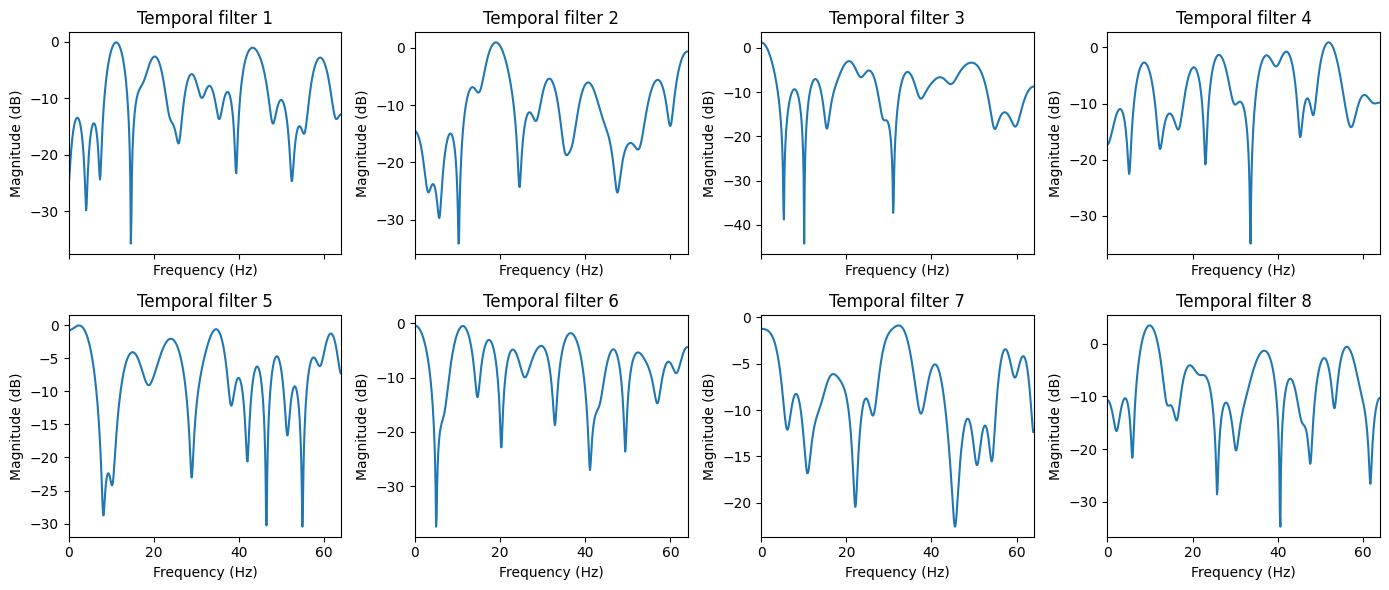

Electrode montage verified.
Number of electrodes: 22


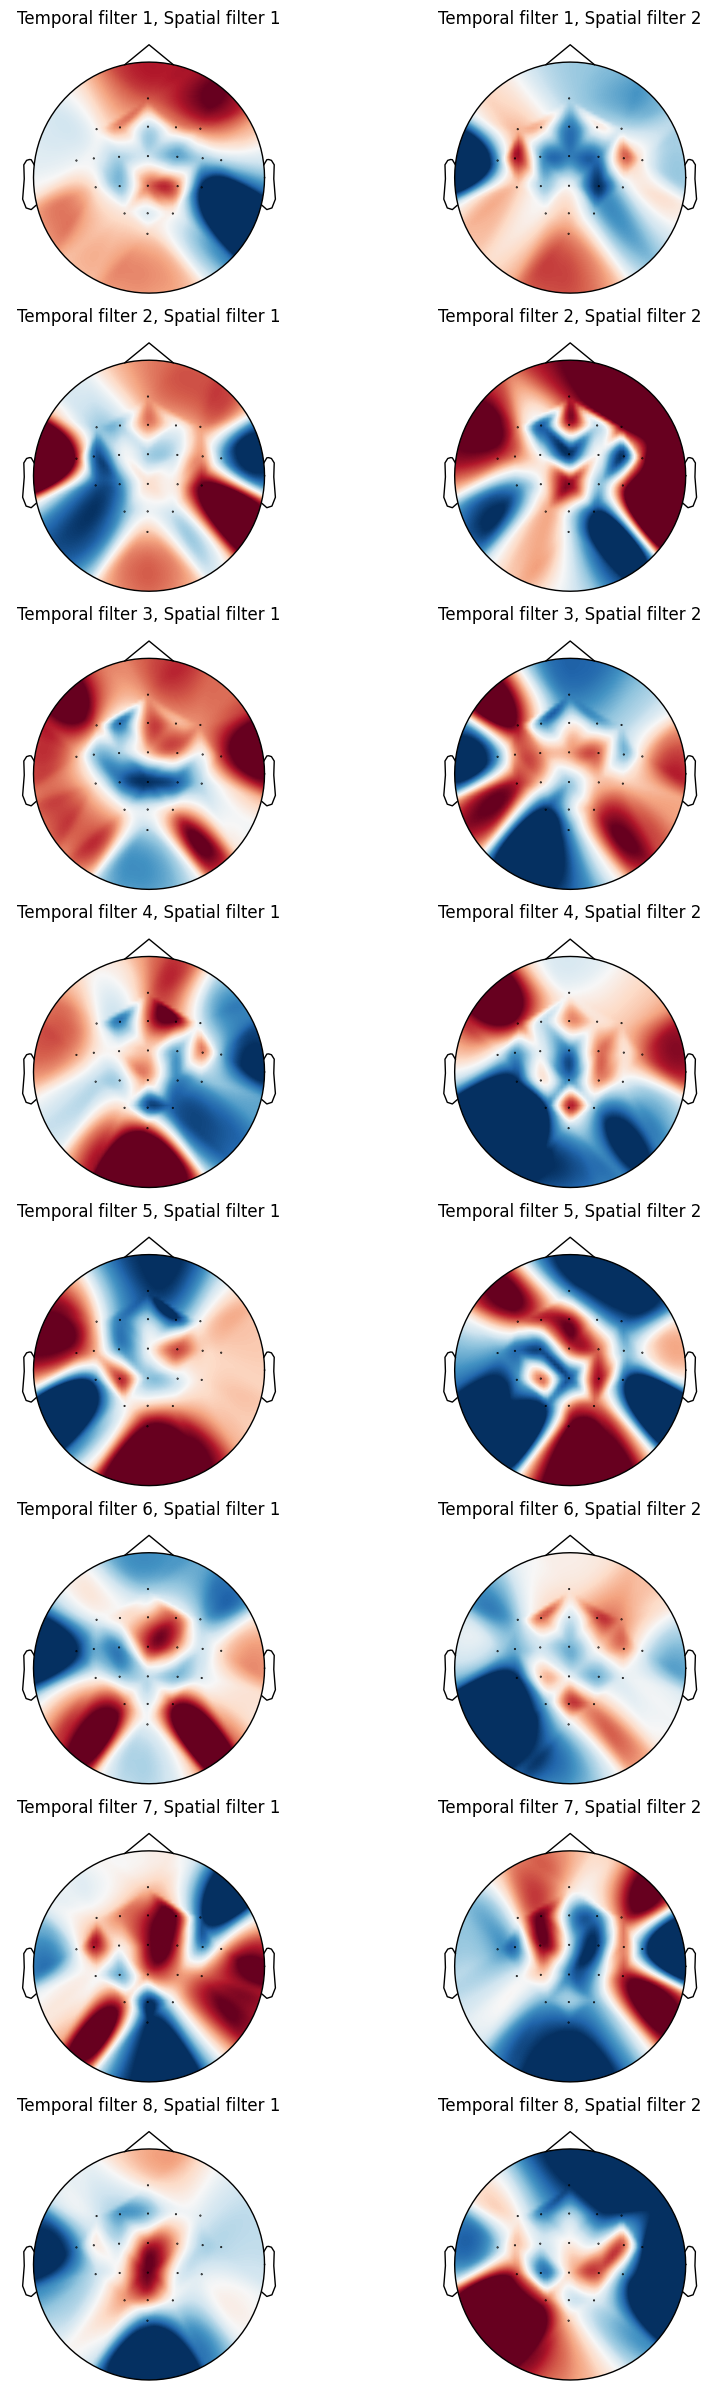

EEGNet filter visualisation completed.


In [14]:

if interpretation_model is None:
    raise RuntimeError("The interpretation model was not retained.")

print(
    f"Interpretation model: held-out subject {interpretation_subject}, "
    f"repeat {interpretation_repeat}"
)

# Plot temporal convolution filters
kernels = interpretation_model.get_layer("temporal_conv").get_weights()[0]
kernels = kernels[0, :, 0, :]

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)

for filter_index, ax in enumerate(axes.flat):
    kernel = kernels[:, filter_index]
    frequencies, response = freqz(
        kernel,
        worN=512,
        fs=TARGET_SFREQ
    )

    ax.plot(frequencies, 20 * np.log10(np.abs(response) + 1e-8))
    ax.set_xlim(0, 64)
    ax.set_title(f"Temporal filter {filter_index + 1}")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Magnitude (dB)")

plt.tight_layout()
plt.show()


# Get spatial filter weights
spatial_weights = interpretation_model.get_layer(
    "spatial_filter"
).get_weights()[0]


# Use the official BCI IV-2a electrode order
plot_channel_names = BCI2A_CHANNELS.copy()

assert len(plot_channel_names) == N_CHANNELS
assert len(set(plot_channel_names)) == N_CHANNELS

# Create electrode information with correct scalp positions
info = mne.create_info(
    ch_names=plot_channel_names,
    sfreq=TARGET_SFREQ,
    ch_types=["eeg"] * N_CHANNELS
)

montage = mne.channels.make_standard_montage("standard_1005")
info.set_montage(montage, on_missing="raise")

# Verify that all electrodes have valid positions
positions = np.array([
    channel["loc"][:3]
    for channel in info["chs"]
])

assert positions.shape == (N_CHANNELS, 3)
assert np.all(np.isfinite(positions))
assert np.all(np.linalg.norm(positions, axis=1) > 0)

print("Electrode montage verified.")
print("Number of electrodes:", len(info["chs"]))


# Plot spatial filter topographies
fig, axes = plt.subplots(
    F1,
    DEPTH_MULTIPLIER,
    figsize=(10, 3 * F1),
    squeeze=False
)

for temporal_index in range(F1):
    for spatial_index in range(DEPTH_MULTIPLIER):

        weights = spatial_weights[
            :, 0, temporal_index, spatial_index
        ]

        ax = axes[temporal_index, spatial_index]

        mne.viz.plot_topomap(
            weights,
            info,
            axes=ax,
            show=False,
            contours=0,
            sensors=True
        )

        ax.set_title(
            f"Temporal filter {temporal_index + 1}, "
            f"Spatial filter {spatial_index + 1}"
        )

plt.tight_layout()
plt.show()

print("EEGNet filter visualisation completed.")


## 10. Single-trial input-gradient relevance

The paper uses DeepLIFT for single-trial feature relevance. This notebook adds an input-gradient relevance map as a transparent supplementary interpretation method; it is **not** an exact reimplementation of DeepLIFT. Positive or negative values are not shown here; the plot displays the magnitude of the input gradient for one held-out trial.

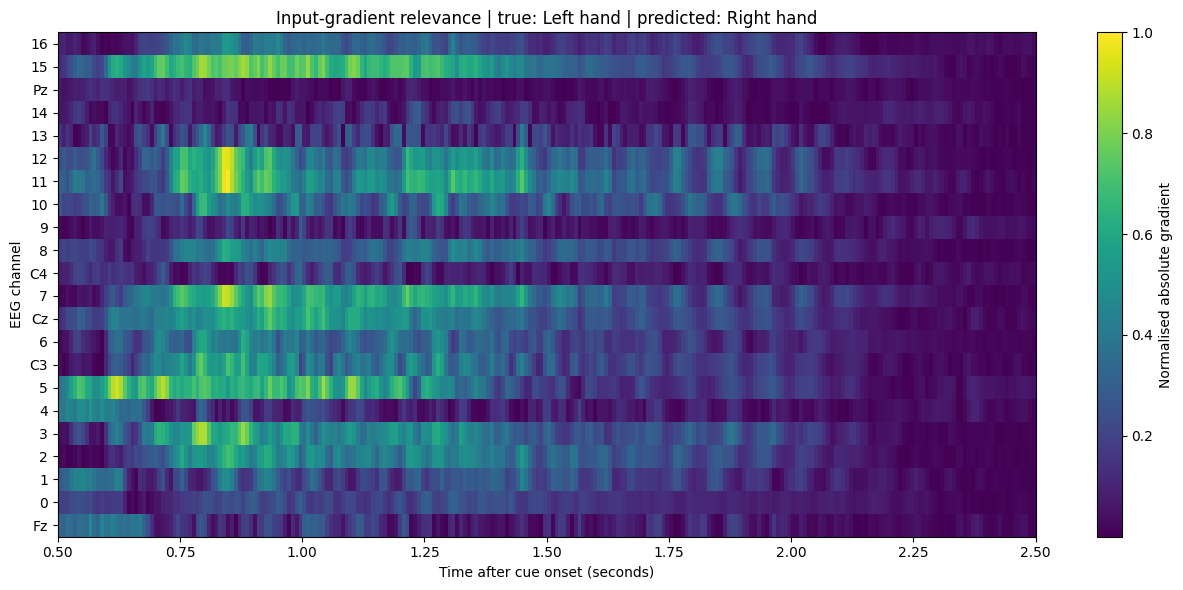

In [15]:
X_interpret = prepare_model_input(subject_data["A01"]["test"]["X"][:1])
y_interpret = subject_data["A01"]["test"]["y"][:1]

input_tensor = tf.convert_to_tensor(X_interpret)
with tf.GradientTape() as tape:
    tape.watch(input_tensor)
    probabilities = interpretation_model(input_tensor, training=False)
    predicted_class = tf.argmax(probabilities[0])
    target_score = probabilities[:, predicted_class]

gradients = tape.gradient(target_score, input_tensor).numpy()[0, :, :, 0]
relevance = np.abs(gradients)
relevance = relevance / (relevance.max() + 1e-12)

plt.figure(figsize=(13, 6))
plt.imshow(
    relevance,
    aspect="auto",
    origin="lower",
    extent=[EPOCH_START, EPOCH_END, 0, N_CHANNELS]
)
plt.yticks(np.arange(N_CHANNELS) + 0.5, clean_channel_names)
plt.xlabel("Time after cue onset (seconds)")
plt.ylabel("EEG channel")
plt.title(
    f"Input-gradient relevance | true: {CLASS_NAMES[int(y_interpret[0])]} | "
    f"predicted: {CLASS_NAMES[int(predicted_class.numpy())]}"
)
plt.colorbar(label="Normalised absolute gradient")
plt.tight_layout()
plt.show()

## 11. Limitations and reproduction notes

1. The reproduced scope is the paper's **SMR cross-subject experiment**, not all four paradigms in the paper.
2. Figure 5 presents benchmark values graphically. The comparison values entered above are visual estimates, not a table of exact published numbers.
3. The paper specifies 500 maximum epochs and validation-based weight selection, but does not report the mini-batch size or early-stopping patience for this experiment. This notebook uses batch size 32 and patience 50; these are explicit implementation choices.
4. The paper refers to the authors' preprocessing software. This notebook uses MNE-Python to implement the stated resampling, filtering and epoching steps. Small implementation differences can change the measured accuracy.
5. The paper's result is stochastic. A different TensorFlow/Keras version, GPU, numerical precision or random initialisation can prevent an exact numerical match even when the protocol is followed.
6. The official evaluation labels are required. Do not substitute guessed labels or use the held-out subject's training session during model fitting.
7. Artifact markers are counted and reported. The notebook retains the task trials rather than applying an additional undocumented artifact-rejection rule.

A reproduction should be judged by whether the published method and evaluation design were followed and whether the obtained results are honestly compared with the paper. Matching the paper's accuracy exactly is not guaranteed.

## 12. Export the results

The following files are written to `/kaggle/working/eegnet_c1_reproduction/results/`:

- `data_quality_summary.csv`
- `eegnet_90_fold_results.csv`
- `subject_accuracy_summary.csv`
- `paper_comparison.csv`

Download these from the Kaggle notebook's **Output** panel after the experiment completes.

In [16]:
print("Saved result files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size:,} bytes)")

print("\nFinal result folder:", OUTPUT_DIR)

Saved result files:
data_quality_summary.csv (921 bytes)
eegnet_90_fold_results.csv (10,258 bytes)
paper_comparison.csv (169 bytes)
subject_accuracy_summary.csv (650 bytes)

Final result folder: /kaggle/working/eegnet_c1_reproduction/results


In [17]:
from pathlib import Path
import pandas as pd

results_dir = Path(
    "/kaggle/working/eegnet_c1_reproduction/results"
)

print("Generated result files:")

for file in sorted(results_dir.rglob("*")):
    if file.is_file():
        print(file.name)

        if file.suffix.lower() == ".csv":
            df = pd.read_csv(file)
            print("Shape:", df.shape)
            display(df.head())

Generated result files:
data_quality_summary.csv
Shape: (9, 12)


,subject,training_trials,evaluation_trials,training_artifact_markers_1023,evaluation_artifact_markers_1023,EEG_channels,sampling_rate_after_resampling,epoch_samples,training_label_counts,evaluation_label_counts,non_finite_training_values,non_finite_evaluation_values
0,A01,288,288,15,7,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
1,A02,288,288,18,5,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
2,A03,288,288,18,15,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
3,A04,288,288,26,60,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0
4,A05,288,288,26,12,22,128.0,256,"[72, 72, 72, 72]","[72, 72, 72, 72]",0,0


eegnet_90_fold_results.csv
Shape: (90, 11)


,target_subject,repeat,training_subjects,validation_subjects,training_trials,validation_trials,test_trials,best_validation_loss,epochs_completed,test_accuracy,test_kappa
0,A01,1,"A02,A05,A07,A08,A09","A03,A04,A06",1440,864,288,1.330150,59,0.472222,0.296296
1,A01,2,"A02,A04,A05,A06,A07","A03,A08,A09",1440,864,288,1.210758,73,0.409722,0.212963
2,A01,3,"A02,A03,A04,A06,A07","A05,A08,A09",1440,864,288,1.269042,69,0.621528,0.495370
3,A01,4,"A04,A05,A06,A08,A09","A02,A03,A07",1440,864,288,1.264805,81,0.600694,0.467593
4,A01,5,"A02,A03,A04,A06,A09","A05,A07,A08",1440,864,288,1.297336,107,0.659722,0.546296


paper_comparison.csv
Shape: (6, 2)


,Method,Paper Figure 5 (visual estimate)
0,FBCSP,0.32
1,DeepConvNet,0.39
2,ShallowConvNet,0.40
3,"EEGNet-4,2",0.40
4,"EEGNet-8,2",0.40


subject_accuracy_summary.csv
Shape: (9, 5)


,target_subject,mean_accuracy,std_accuracy,folds,mean_accuracy_percent
0,A01,0.531944,0.124127,10,53.194444
1,A02,0.279514,0.025265,10,27.951389
2,A03,0.536806,0.134729,10,53.680556
3,A04,0.332986,0.055639,10,33.298611
4,A05,0.262847,0.015704,10,26.284722


In [20]:

import os
import shutil
import zipfile
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import mne

from IPython.display import display, FileLink

WORK_DIR = Path("/kaggle/working")
RESULTS_DIR = WORK_DIR / "eegnet_c1_reproduction" / "results"

EXPORT_DIR = WORK_DIR / "EEGNet_C1_Final_Export"
ZIP_PATH = WORK_DIR / "EEGNet_C1_Final_Results.zip"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(f"Results directory not found: {RESULTS_DIR}")

# Create a clean export directory
if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)

EXPORT_DIR.mkdir(parents=True)

# Copy all generated CSV files
csv_files = list(RESULTS_DIR.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV result files were found.")

for file in csv_files:
    shutil.copy2(file, EXPORT_DIR / file.name)

# Save experiment summary directly from the 90-fold CSV
fold_path = EXPORT_DIR / "eegnet_90_fold_results.csv"

if fold_path.exists():
    folds = pd.read_csv(fold_path)

    subject_summary = (
        folds.groupby("target_subject")["test_accuracy"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    subject_summary.to_csv(
        EXPORT_DIR / "subject_accuracy_summary.csv",
        index=False
    )

    summary = {
        "completed_folds": int(len(folds)),
        "mean_accuracy": float(folds["test_accuracy"].mean()),
        "standard_deviation": float(folds["test_accuracy"].std()),
        "mean_kappa": float(folds["test_kappa"].mean()),
        "chance_accuracy": 0.25,
        "tensorflow_version": tf.__version__,
        "mne_version": mne.__version__,
        "python_version": platform.python_version()
    }

    with open(EXPORT_DIR / "experiment_metadata.json", "w") as f:
        json.dump(summary, f, indent=4)

    assert len(folds) == 90

# Save currently open figures
FIGURES_DIR = EXPORT_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

for number in plt.get_fignums():
    fig = plt.figure(number)
    fig.savefig(
        FIGURES_DIR / f"figure_{number}.png",
        dpi=300,
        bbox_inches="tight"
    )

# Include previously saved model files, if present
model_files = []

for file in WORK_DIR.rglob("*"):
    if not file.is_file():
        continue

    if EXPORT_DIR in file.parents or file == ZIP_PATH:
        continue

    if file.suffix == ".keras" or file.name.endswith(".weights.h5"):
        model_files.append(file)

MODEL_DIR = EXPORT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

for file in model_files:
    shutil.copy2(file, MODEL_DIR / file.name)

# Create ZIP at the top level of Kaggle working directory
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file in EXPORT_DIR.rglob("*"):
        if file.is_file():
            archive.write(
                file,
                file.relative_to(EXPORT_DIR)
            )

# Verify the ZIP
assert ZIP_PATH.exists()
assert zipfile.is_zipfile(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    assert bad_file is None, f"ZIP verification failed: {bad_file}"

print("Export completed successfully.")
print("ZIP location:", ZIP_PATH)
print("ZIP size:", round(ZIP_PATH.stat().st_size / 1024**2, 2), "MB")
print("CSV files:", len(csv_files))
print("Saved model files:", len(model_files))

# Display a Kaggle download link
os.chdir(WORK_DIR)
display(FileLink("EEGNet_C1_Final_Results.zip"))


Export completed successfully.
ZIP location: /kaggle/working/EEGNet_C1_Final_Results.zip
ZIP size: 0.05 MB
CSV files: 4
Saved model files: 2


/kaggle/working/EEGNet_C1_Final_Results.zip

In [19]:
print("COMPLETE SUBJECT-WISE RESULTS")
display(subject_summary)

print("\nCOMPLETE PAPER COMPARISON")
display(comparison_table)

print("\nOVERALL EXPERIMENT SUMMARY")
display(summary_table)

print("\nFINAL METRICS")

print("Completed folds:", len(fold_results))

print(
    "Overall accuracy:",
    round(fold_results["test_accuracy"].mean() * 100, 2),
    "%"
)

print(
    "Accuracy standard deviation:",
    round(fold_results["test_accuracy"].std(ddof=1) * 100, 2),
    "%"
)

print(
    "Mean Cohen's kappa:",
    round(fold_results["test_kappa"].mean(), 4)
)

assert len(fold_results) == 90
assert subject_summary["folds"].sum() == 90

print("\nAll 90 folds verified.")

COMPLETE SUBJECT-WISE RESULTS


,target_subject,mean_accuracy,std_accuracy,folds,mean_accuracy_percent
0,A01,0.531944,0.124127,10,53.194444
1,A02,0.279514,0.025265,10,27.951389
2,A03,0.536806,0.134729,10,53.680556
3,A04,0.332986,0.055639,10,33.298611
4,A05,0.262847,0.015704,10,26.284722
5,A06,0.295139,0.035674,10,29.513889
6,A07,0.289236,0.054362,10,28.923611
7,A08,0.507639,0.143040,10,50.763889
8,A09,0.360417,0.060425,10,36.041667



COMPLETE PAPER COMPARISON


,Method,Paper Figure 5 (visual estimate)
0,FBCSP,0.320000
1,DeepConvNet,0.390000
2,ShallowConvNet,0.400000
3,"EEGNet-4,2",0.400000
4,"EEGNet-8,2",0.400000
5,"Our EEGNet-8,2 reproduction",0.377392



OVERALL EXPERIMENT SUMMARY


,Metric,Value
0,Number of folds,90.000000
1,Mean accuracy,0.377392
2,Standard deviation,0.136181
3,Standard error of the mean,0.014355
4,Two standard errors,0.028709
5,Mean Cohen's kappa,0.169856
6,Chance-level accuracy,0.250000



FINAL METRICS
Completed folds: 90
Overall accuracy: 37.74 %
Accuracy standard deviation: 13.62 %
Mean Cohen's kappa: 0.1699

All 90 folds verified.
